# 07 · Training Class-Balance Experiments (30/70 … 70/30)

**Purpose.** This notebook asks how sensitive the models, and TabPFN in particular, are to the *class balance of the training subset*
while the external test set stays untouched (natural prevalence).

**Convention.** `class_ratio` = fraction of the **positive** class in the training subset
(0.3 means 30 % positive / 70 % negative). 0.5 is re-run here with the same sampler so that every
ratio is compared under identical conditions (paired design).

**Design choices**
- For each (dataset, seed) one random permutation of the positive pool and one of the negative pool
  is drawn. A subset of size *n* with ratio *r* takes the first `round(n*r)` positives and the rest
  negatives. Consequences: subsets are **nested across sizes** and **paired across ratios**.
- Models: default Logistic Regression (LR), Random Forest (RF), XGBoost (as in 03) and TabPFN V3 (as in 04).
  No hyperparameter optimisation (HPO) is performed in this class-balance experiment; all conventional models use their configured default settings.
- Besides the original metrics, **prior-corrected** metrics are reported (Bayes prior-shift
  correction to the test prevalence) together with Brier, log-loss and ECE. ROC-AUC and PR-AUC are
  invariant to this correction.

In [1]:
# ============================================================
# Cell 1 - Environment and protocol imports
# ============================================================
import os, sys, time, pickle, json, zlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import xgboost as xgb
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics as skm

warnings.filterwarnings("ignore", category=FutureWarning)


def find_code_dir():
    env = os.environ.get("THESIS_CODE_DIR")
    if env:
        return Path(env).resolve()
    cands = []
    cwd = Path.cwd()
    if (cwd / "data_pipeline.py").exists() and (cwd / "experiment_protocol.py").exists():
        cands.append(cwd)
    kin = Path("/kaggle/input")
    if kin.exists():
        for f in kin.rglob("data_pipeline.py"):
            if (f.parent / "experiment_protocol.py").exists():
                cands.append(f.parent)
    cands = list(dict.fromkeys(p.resolve() for p in cands))
    if len(cands) != 1:
        raise RuntimeError(f"Expected exactly one code directory, found: {cands}. Set THESIS_CODE_DIR.")
    return cands[0]


CODE_DIR = find_code_dir()
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from data_pipeline import load_prepared_experiment
from experiment_protocol import (
    PROTOCOL_VERSION, EXPECTED_DATASETS, TRAINING_SIZES, SUBSET_SEEDS,
    TEST_SIZE, TEST_SEED, MODEL_SEED,
    CLASSIFICATION_THRESHOLD, LOGISTIC_REGRESSION_MAX_ITER,
    XGBOOST_OBJECTIVE, XGBOOST_EVAL_METRIC,
    TABPFN_MODEL_VERSION,
)

RESULTS_DIR = Path(os.environ.get("THESIS_RESULTS_DIR", "/kaggle/working"))
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"sklearn {sklearn.__version__} | xgboost {xgb.__version__}")
print(f"Protocol: {PROTOCOL_VERSION} | code dir: {CODE_DIR}")

Python 3.13.16 | numpy 2.1.3 | pandas 2.3.3 | sklearn 1.6.1 | xgboost 3.4.1
Protocol: low_data_tabpfn_v1 | code dir: /kaggle/input/datasets/nicolausdeemese/thesis-nicolas/thesis


In [7]:
# ============================================================
# Cell 2 - Study configuration
# ============================================================
STUDY_VERSION = "class_balance_v1"

# Fraction of POSITIVE class in the training subset. 0.5 is re-run for a paired comparison.
CLASS_RATIOS = (0.3, 0.4, 0.6, 0.7)

# Subset of the protocol training sizes (keeps the study affordable).
SIZES = (128, 512, 2048, 8192)

# Seeds used for subset sampling. Default = protocol seeds; more seeds (e.g. 10) give tighter estimates.
SEEDS = tuple(SUBSET_SEEDS)

RUN_TABPFN = True      # needs tabpfn package + TABPFN_TOKEN (GPU strongly recommended)
PREDICTION_BATCH_SIZE = 1000
TABPFN_PACKAGE_VERSION = "8.3.0"

assert all(s in TRAINING_SIZES for s in SIZES), "SIZES must be a subset of the protocol sizes."
assert all(0.0 < r < 1.0 for r in CLASS_RATIOS)
CLASS_RATIOS = tuple(round(r, 2) for r in CLASS_RATIOS)

ACTIVE_MODELS = ["logistic_regression", "random_forest", "xgboost"]
if RUN_TABPFN:
    ACTIVE_MODELS.append("tabpfn_v3")

n_runs = len(EXPECTED_DATASETS) * len(CLASS_RATIOS) * len(SIZES) * len(SEEDS) * len(ACTIVE_MODELS)
print(f"Ratios: {CLASS_RATIOS}\nSizes: {SIZES}\nSeeds: {SEEDS}\nModels: {ACTIVE_MODELS}\nTotal runs: {n_runs}")

Ratios: (0.3, 0.4, 0.6, 0.7)
Sizes: (128, 512, 2048, 8192)
Seeds: (42, 123, 456, 789, 1011)
Models: ['logistic_regression', 'random_forest', 'xgboost', 'tabpfn_v3']
Total runs: 640


In [8]:
# ============================================================
# Cell 3 - Install TabPFN and set the token
# ============================================================
if RUN_TABPFN:
    import subprocess

    assert TABPFN_MODEL_VERSION == "V3", (
        "This notebook assumes TabPFN V3 as in notebook 04."
    )

    # Check whether the required TabPFN version is installed
    try:
        import tabpfn
        installed = tabpfn.__version__
    except ImportError:
        installed = None

    # Install the required version if necessary
    if installed != TABPFN_PACKAGE_VERSION:
        r = subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "--no-cache-dir",
                f"tabpfn=={TABPFN_PACKAGE_VERSION}"
            ],
            capture_output=True,
            text=True
        )

        if r.returncode != 0:
            print(r.stdout, r.stderr)
            raise RuntimeError("TabPFN installation failed.")

    import tabpfn

    assert tabpfn.__version__ == TABPFN_PACKAGE_VERSION, (
        f"Expected TabPFN {TABPFN_PACKAGE_VERSION}, "
        f"but found {tabpfn.__version__}."
    )

    # Retrieve the API token from Kaggle Secrets
    if not os.environ.get("TABPFN_TOKEN"):
        from kaggle_secrets import UserSecretsClient

        user_secrets = UserSecretsClient()
        secret_value = user_secrets.get_secret("TabPFN-3 API final")

        os.environ["TABPFN_TOKEN"] = secret_value.strip()

    # Verify that the token was loaded successfully
    assert os.environ.get("TABPFN_TOKEN"), (
        "TabPFN API token is missing. "
        "Check that the Kaggle secret 'TabPFN-3 API final' "
        "exists and is enabled for this notebook."
    )

    import torch

    print(
        "TabPFN", tabpfn.__version__,
        "| API token loaded successfully:",
        bool(os.environ.get("TABPFN_TOKEN")),
        "| CUDA available:",
        torch.cuda.is_available()
    )

else:
    print("TabPFN disabled.")

TabPFN 8.3.0 | API token loaded successfully: True | CUDA available: True


In [9]:
# ============================================================
# Cell 4 - Load the prepared experiment (read-only) and check consistency
# ============================================================
experiment_data = load_prepared_experiment()
split_data = experiment_data["split_data"]
config = experiment_data["config"]

assert tuple(split_data.keys()) == tuple(EXPECTED_DATASETS)
assert config["test_size"] == TEST_SIZE and config["test_seed"] == TEST_SEED
assert config["n_classes"] == 2

POOLS = {}
for ds in EXPECTED_DATASETS:
    y_tr, y_te = split_data[ds]["y_train"], split_data[ds]["y_test"]
    assert y_tr.index.is_unique and y_te.index.is_unique
    assert set(y_tr.index).isdisjoint(set(y_te.index))
    assert set(np.unique(y_tr)) == {0, 1} and set(np.unique(y_te)) == {0, 1}
    POOLS[ds] = {
        "train_pos": int((y_tr == 1).sum()),
        "train_neg": int((y_tr == 0).sum()),
        "test_rows": len(y_te),
        "test_prevalence": float(y_te.mean()),
    }

display(pd.DataFrame(POOLS).T)

# Feasibility: can the pools supply the most extreme requested subset?
max_size = max(SIZES)
for ds in EXPECTED_DATASETS:
    need_pos = max(int(round(max_size * r)) for r in CLASS_RATIOS)
    need_neg = max(max_size - int(round(max_size * r)) for r in CLASS_RATIOS)
    assert POOLS[ds]["train_pos"] >= need_pos, f"{ds}: not enough positives ({need_pos} needed)."
    assert POOLS[ds]["train_neg"] >= need_neg, f"{ds}: not enough negatives ({need_neg} needed)."
    print(f"{ds}: pools sufficient (need up to {need_pos} pos / {need_neg} neg).")

,train_pos,train_neg,test_rows,test_prevalence
diabetes,28078.0,155501.0,45895.0,0.152936
cardiovascular,27158.0,27731.0,13723.0,0.494790


diabetes: pools sufficient (need up to 5734 pos / 5734 neg).
cardiovascular: pools sufficient (need up to 5734 pos / 5734 neg).


In [10]:
# ============================================================
# Cell 5 - Build ratio subsets (nested over sizes, paired over ratios)
# ============================================================
def build_ratio_subsets(dataset, y_train, ratios, sizes, seeds):
    pos_pool = y_train.index[y_train == 1].to_numpy()
    neg_pool = y_train.index[y_train == 0].to_numpy()
    out = {}
    for seed in seeds:
        rng = np.random.default_rng([int(seed), zlib.crc32(dataset.encode("utf-8"))])
        pos_perm = rng.permutation(pos_pool)
        neg_perm = rng.permutation(neg_pool)
        for ratio in ratios:
            for size in sizes:
                n_pos = int(round(size * ratio))
                n_neg = size - n_pos
                idx = np.concatenate([pos_perm[:n_pos], neg_perm[:n_neg]])
                # deterministic shuffle so row order carries no class information
                order = np.random.default_rng([int(seed), int(size), int(round(ratio * 100))]).permutation(len(idx))
                out[(ratio, size, seed)] = idx[order]
    return out


SUBSETS = {ds: build_ratio_subsets(ds, split_data[ds]["y_train"], CLASS_RATIOS, SIZES, SEEDS)
           for ds in EXPECTED_DATASETS}

# ---- integrity checks ----
for ds in EXPECTED_DATASETS:
    y_tr = split_data[ds]["y_train"]
    train_idx = set(y_tr.index)
    test_idx = set(split_data[ds]["y_test"].index)
    for (ratio, size, seed), idx in SUBSETS[ds].items():
        assert len(idx) == size and len(set(idx)) == size
        s = set(idx)
        assert s <= train_idx and s.isdisjoint(test_idx)
        n_pos = int((y_tr.loc[idx] == 1).sum())
        assert n_pos == int(round(size * ratio)), (ds, ratio, size, seed, n_pos)
    # nesting across sizes (same ratio and seed)
    for ratio in CLASS_RATIOS:
        for seed in SEEDS:
            prev = None
            for size in sorted(SIZES):
                cur = set(SUBSETS[ds][(ratio, size, seed)])
                if prev is not None:
                    assert prev <= cur, f"Not nested: {ds}, ratio={ratio}, seed={seed}, size={size}"
                prev = cur
    # pairing across ratios: subsets of different ratios share rows
    ov = len(set(SUBSETS[ds][(CLASS_RATIOS[0], max(SIZES), SEEDS[0])]) &
             set(SUBSETS[ds][(CLASS_RATIOS[-1], max(SIZES), SEEDS[0])]))
    print(f"{ds}: {len(SUBSETS[ds])} subsets verified | rows shared by lowest and highest ratio at n={max(SIZES)}: {ov}")

# ---- determinism ----
for ds in EXPECTED_DATASETS:
    again = build_ratio_subsets(ds, split_data[ds]["y_train"], CLASS_RATIOS, SIZES, SEEDS)
    assert all(np.array_equal(again[k], SUBSETS[ds][k]) for k in again)
print("Subsampling is deterministic.")

# class counts table for the thesis
rows = [{"size": n, "ratio": r, "n_pos": int(round(n * r)), "n_neg": n - int(round(n * r))}
        for r in CLASS_RATIOS for n in SIZES]
display(pd.DataFrame(rows).pivot(index="size", columns="ratio", values="n_pos").rename_axis("positives per subset"))

diabetes: 80 subsets verified | rows shared by lowest and highest ratio at n=8192: 4916
cardiovascular: 80 subsets verified | rows shared by lowest and highest ratio at n=8192: 4916
Subsampling is deterministic.


ratio,0.3,0.4,0.6,0.7
positives per subset,,,,
128,38,51,77,90
512,154,205,307,358
2048,614,819,1229,1434
8192,2458,3277,4915,5734


In [11]:
# ============================================================
# Cell 6 - Metrics (raw + prior-corrected)
# ============================================================
EPS = 1e-6


def prior_correct(p, pi_train, pi_test):
    # Bayes prior-shift correction of probabilities from a model trained with positive prior pi_train
    p = np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)
    w1 = pi_test / pi_train
    w0 = (1 - pi_test) / (1 - pi_train)
    return p * w1 / (p * w1 + (1 - p) * w0)


def expected_calibration_error(y, p, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1)
    ids = np.clip(np.digitize(p, edges[1:-1]), 0, n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        m = ids == b
        if m.any():
            ece += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(ece)


def evaluate(y_true, p_raw, pi_train):
    y = np.asarray(y_true).astype(int)
    assert set(np.unique(y)) == {0, 1}
    pi_test = float(y.mean())
    p_raw = np.clip(np.asarray(p_raw, dtype=float), EPS, 1 - EPS)
    assert np.isfinite(p_raw).all() and len(p_raw) == len(y)
    p_cor = prior_correct(p_raw, pi_train, pi_test)

    yh_raw = (p_raw >= CLASSIFICATION_THRESHOLD).astype(int)
    yh_cor = (p_cor >= CLASSIFICATION_THRESHOLD).astype(int)
    pr = float(skm.average_precision_score(y, p_raw))

    def prf(yh):
        return (float(skm.precision_score(y, yh, zero_division=0)),
                float(skm.recall_score(y, yh, zero_division=0)),
                float(skm.f1_score(y, yh, zero_division=0)))

    pr_raw, rc_raw, f1_raw = prf(yh_raw)
    pr_cor, rc_cor, f1_cor = prf(yh_cor)
    return {
        # threshold-free (invariant to the prior correction)
        "roc_auc": float(skm.roc_auc_score(y, p_raw)),
        "pr_auc": pr,
        "pr_auc_lift": pr - pi_test,
        # threshold 0.5 on raw outputs (reflects the training prior)
        "accuracy_raw": float(skm.accuracy_score(y, yh_raw)),
        "balanced_accuracy_raw": float(skm.balanced_accuracy_score(y, yh_raw)),
        "precision_raw": pr_raw, "recall_raw": rc_raw, "f1_raw": f1_raw,
        # threshold 0.5 on prior-corrected probabilities
        "balanced_accuracy_corr": float(skm.balanced_accuracy_score(y, yh_cor)),
        "precision_corr": pr_cor, "recall_corr": rc_cor, "f1_corr": f1_cor,
        # probability quality
        "log_loss_raw": float(skm.log_loss(y, p_raw, labels=[0, 1])),
        "log_loss_corr": float(skm.log_loss(y, p_cor, labels=[0, 1])),
        "brier_raw": float(skm.brier_score_loss(y, p_raw)),
        "brier_corr": float(skm.brier_score_loss(y, p_cor)),
        "ece_corr": expected_calibration_error(y, p_cor),
    }


# sanity: correction is the identity when priors are equal and monotone otherwise
_p = np.linspace(0.01, 0.99, 50)
assert np.allclose(prior_correct(_p, 0.5, 0.5), _p)
assert np.all(np.diff(prior_correct(_p, 0.5, 0.15)) > 0)
METRIC_COLUMNS = list(evaluate(np.array([0, 1, 0, 1]), np.array([0.2, 0.7, 0.4, 0.6]), 0.5).keys())
print("Metrics:", METRIC_COLUMNS)

Metrics: ['roc_auc', 'pr_auc', 'pr_auc_lift', 'accuracy_raw', 'balanced_accuracy_raw', 'precision_raw', 'recall_raw', 'f1_raw', 'balanced_accuracy_corr', 'precision_corr', 'recall_corr', 'f1_corr', 'log_loss_raw', 'log_loss_corr', 'brier_raw', 'brier_corr', 'ece_corr']


In [12]:
# ============================================================
# Cell 7 - Model factories (same settings as notebooks 03 and 04)
# ============================================================
def _lr_pipeline():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(random_state=MODEL_SEED, max_iter=LOGISTIC_REGRESSION_MAX_ITER)),
    ])


def make_model(name):
    if name == "logistic_regression":
        return _lr_pipeline()
    if name == "random_forest":
        return RandomForestClassifier(random_state=MODEL_SEED)
    if name == "xgboost":
        return xgb.XGBClassifier(objective=XGBOOST_OBJECTIVE, eval_metric=XGBOOST_EVAL_METRIC,
                                 random_state=MODEL_SEED)
    if name == "tabpfn_v3":
        from tabpfn import TabPFNClassifier
        from tabpfn.constants import ModelVersion
        return TabPFNClassifier.create_default_for_version(
            ModelVersion.V3, device="auto", random_state=MODEL_SEED,
            n_estimators="auto", show_progress_bar=False)
    raise ValueError(name)


def predict_positive_proba(model, X, batch_size=None):
    if batch_size is None:
        proba = np.asarray(model.predict_proba(X))
    else:
        parts = [np.asarray(model.predict_proba(X.iloc[i:i + batch_size])) for i in range(0, len(X), batch_size)]
        proba = np.vstack(parts)
    assert np.array_equal(np.asarray(model.classes_), np.array([0, 1])), "Unexpected class order."
    return proba[:, 1]


def run_one(ds, model_name, ratio, size, seed):
    idx = SUBSETS[ds][(ratio, size, seed)]
    X_tr = split_data[ds]["X_train"].loc[idx]
    y_tr = split_data[ds]["y_train"].loc[idx]
    X_te, y_te = split_data[ds]["X_test"], split_data[ds]["y_test"]
    assert X_tr.shape[1] == X_te.shape[1]
    pi_train = float(y_tr.mean())
    assert abs(pi_train - ratio) <= 0.5 / size + 1e-9

    model = make_model(model_name)
    t0 = time.perf_counter()
    model.fit(X_tr, y_tr)
    fit_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    p = predict_positive_proba(model, X_te, PREDICTION_BATCH_SIZE if model_name == "tabpfn_v3" else None)
    predict_time = time.perf_counter() - t0

    return {
        "study_version": STUDY_VERSION, "protocol_version": PROTOCOL_VERSION,
        "dataset": ds, "model": model_name, "class_ratio": ratio,
        "training_size": int(size), "subset_seed": int(seed), "model_seed": MODEL_SEED,
        "n_pos_train": int((y_tr == 1).sum()), "n_neg_train": int((y_tr == 0).sum()),
        "test_prevalence": float(y_te.mean()),
        "fit_time": float(fit_time), "predict_time": float(predict_time),
        **evaluate(y_te, p, pi_train),
    }


# ---- smoke test (not stored) ----
t = run_one(EXPECTED_DATASETS[0], "logistic_regression", CLASS_RATIOS[0], SIZES[1], SEEDS[0])
print({k: round(v, 4) if isinstance(v, float) else v for k, v in t.items() if k in
       ("dataset", "model", "class_ratio", "training_size", "roc_auc", "pr_auc", "recall_raw", "recall_corr", "log_loss_corr")})
for k in METRIC_COLUMNS:
    assert np.isfinite(t[k])
print("Smoke test passed.")

{'dataset': 'diabetes', 'model': 'logistic_regression', 'class_ratio': 0.3, 'training_size': 512, 'roc_auc': 0.793, 'pr_auc': 0.3855, 'recall_raw': 0.5065, 'recall_corr': 0.2374, 'log_loss_corr': 0.3615}
Smoke test passed.


In [13]:
# ============================================================
# Cell 8 - Checkpointed full run (resumable)
# ============================================================
CHECKPOINT_PATH = RESULTS_DIR / f"{STUDY_VERSION}_checkpoint.pkl"
CHECKPOINT_META = {
    "study_version": STUDY_VERSION, "protocol_version": PROTOCOL_VERSION,
    "class_ratios": CLASS_RATIOS, "sizes": tuple(SIZES), "seeds": tuple(SEEDS),
    "model_seed": MODEL_SEED,
    "prediction_batch_size": PREDICTION_BATCH_SIZE,
}


def run_key(r):
    return (r["dataset"], r["model"], round(r["class_ratio"], 2), int(r["training_size"]), int(r["subset_seed"]))


def save_checkpoint(results):
    tmp = CHECKPOINT_PATH.with_suffix(".tmp")
    with open(tmp, "wb") as fh:
        pickle.dump({"metadata": CHECKPOINT_META, "results": results}, fh, protocol=pickle.HIGHEST_PROTOCOL)
    tmp.replace(CHECKPOINT_PATH)


def load_checkpoint():
    with open(CHECKPOINT_PATH, "rb") as fh:
        payload = pickle.load(fh)
    assert payload["metadata"] == CHECKPOINT_META, "Checkpoint metadata differs from the current configuration."
    return payload["results"]


results = load_checkpoint() if CHECKPOINT_PATH.exists() else []
done = {run_key(r) for r in results}
assert len(done) == len(results), "Duplicate keys in checkpoint."

expected_keys = {(ds, m, r, n, s) for ds in EXPECTED_DATASETS for m in ACTIVE_MODELS
                 for r in CLASS_RATIOS for n in SIZES for s in SEEDS}
print(f"Expected {len(expected_keys)} | already done {len(done & expected_keys)} | remaining {len(expected_keys - done)}")

t_start = time.perf_counter()
counter = len(done & expected_keys)
for ds in EXPECTED_DATASETS:
    for ratio in CLASS_RATIOS:
        for size in SIZES:
            for seed in SEEDS:
                for model_name in ACTIVE_MODELS:
                    key = (ds, model_name, ratio, size, seed)
                    if key in done:
                        continue
                    res = run_one(ds, model_name, ratio, size, seed)
                    assert run_key(res) == key
                    for k in METRIC_COLUMNS:
                        assert np.isfinite(res[k]), (key, k)
                    results.append(res)
                    done.add(key)
                    save_checkpoint(results)
                    counter += 1
                    print(f"[{counter}/{len(expected_keys)}] {ds:14s} {model_name:24s} r={ratio:.1f} n={size:5d} "
                          f"seed={seed:4d} ROC={res['roc_auc']:.4f} PR={res['pr_auc']:.4f} "
                          f"fit={res['fit_time']:.1f}s pred={res['predict_time']:.1f}s")

assert expected_keys <= done
print(f"Finished. Elapsed this session: {time.perf_counter() - t_start:.0f} s")

Expected 640 | already done 0 | remaining 640
[1/640] diabetes       logistic_regression      r=0.3 n=  128 seed=  42 ROC=0.7287 PR=0.2975 fit=0.0s pred=0.0s
[2/640] diabetes       random_forest            r=0.3 n=  128 seed=  42 ROC=0.7454 PR=0.3378 fit=0.2s pred=0.2s
[3/640] diabetes       xgboost                  r=0.3 n=  128 seed=  42 ROC=0.7234 PR=0.3128 fit=0.3s pred=0.0s


tabpfn-v3-classifier-v3_default.ckpt: reconstructing file:   0%|          |  0.00B /  213MB            

tabpfn-v3-classifier-v3_default.ckpt: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/33.0 [00:00<?, ?B/s]

[4/640] diabetes       tabpfn_v3                r=0.3 n=  128 seed=  42 ROC=0.7659 PR=0.3644 fit=5.7s pred=26.9s
[5/640] diabetes       logistic_regression      r=0.3 n=  128 seed= 123 ROC=0.7795 PR=0.3716 fit=0.0s pred=0.0s
[6/640] diabetes       random_forest            r=0.3 n=  128 seed= 123 ROC=0.7633 PR=0.3435 fit=0.2s pred=0.2s
[7/640] diabetes       xgboost                  r=0.3 n=  128 seed= 123 ROC=0.7404 PR=0.3262 fit=0.0s pred=0.0s
[8/640] diabetes       tabpfn_v3                r=0.3 n=  128 seed= 123 ROC=0.7832 PR=0.3755 fit=0.8s pred=24.5s
[9/640] diabetes       logistic_regression      r=0.3 n=  128 seed= 456 ROC=0.7455 PR=0.3459 fit=0.0s pred=0.0s
[10/640] diabetes       random_forest            r=0.3 n=  128 seed= 456 ROC=0.7726 PR=0.3679 fit=0.2s pred=0.2s
[11/640] diabetes       xgboost                  r=0.3 n=  128 seed= 456 ROC=0.7434 PR=0.3230 fit=0.0s pred=0.0s
[12/640] diabetes       tabpfn_v3                r=0.3 n=  128 seed= 456 ROC=0.7850 PR=0.3819 fit=0.

In [15]:
# ============================================================
# Cell 9 - Validate and export results
# ============================================================

# Convert experiment results into a DataFrame
df_all = pd.DataFrame(results)

# Keep only the models active in this experiment
df = df_all[df_all["model"].isin(ACTIVE_MODELS)].copy()

# Standardize class ratios
df["class_ratio"] = df["class_ratio"].round(2)

# ------------------------------------------------------------
# Validate experiment completeness
# ------------------------------------------------------------

keys = set(
    zip(
        df.dataset,
        df.model,
        df.class_ratio,
        df.training_size,
        df.subset_seed
    )
)

assert keys == expected_keys and len(df) == len(expected_keys), (
    "Experiment results are incomplete or contain unexpected runs."
)

# Validate that all required metrics are available
assert df[METRIC_COLUMNS].notna().all().all(), (
    "Some evaluation metrics contain missing values."
)

# Validate training subset sizes
assert (
    df["n_pos_train"] + df["n_neg_train"]
    == df["training_size"]
).all(), "Positive and negative counts do not match training size."

# ------------------------------------------------------------
# Sort and export results
# ------------------------------------------------------------

df = df.sort_values(
    [
        "dataset",
        "model",
        "class_ratio",
        "training_size",
        "subset_seed"
    ]
).reset_index(drop=True)

CSV_PATH = RESULTS_DIR / f"{STUDY_VERSION}_results.csv"

df.to_csv(CSV_PATH, index=False)

print(f"{len(df)} rows saved to {CSV_PATH}")

# ------------------------------------------------------------
# Analysis configuration
# ------------------------------------------------------------

MODEL_ORDER = [
    m for m in [
        "logistic_regression",
        "random_forest",
        "xgboost",
        "tabpfn_v3"
    ]
    if m in ACTIVE_MODELS
]

# Training sizes used for focused plots
FOCUS_SIZES = [
    s for s in (128, 512, 8192)
    if s in SIZES
]

# All tested ratios are treated as experimental conditions.
NON_BASE = list(CLASS_RATIOS)

print("\nAnalysis configuration:")
print("Models:", MODEL_ORDER)
print("Training sizes:", FOCUS_SIZES)
print("Class ratios:", NON_BASE)

# ------------------------------------------------------------
# Figure-saving function
# ------------------------------------------------------------

def savefig(fig, name):
    fig.savefig(
        RESULTS_DIR / f"{STUDY_VERSION}_{name}.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()


print("\nResults validated and exported successfully.")

640 rows saved to /kaggle/working/class_balance_v1_results.csv

Analysis configuration:
Models: ['logistic_regression', 'random_forest', 'xgboost', 'tabpfn_v3']
Training sizes: [128, 512, 8192]
Class ratios: [0.3, 0.4, 0.6, 0.7]

Results validated and exported successfully.


## Analysis

### A. Learning curves per training ratio
ROC-AUC and PR-AUC are invariant to the prior correction, so differences between ratios here reflect
a genuine change in the *ranking* quality of the model, not a threshold effect.

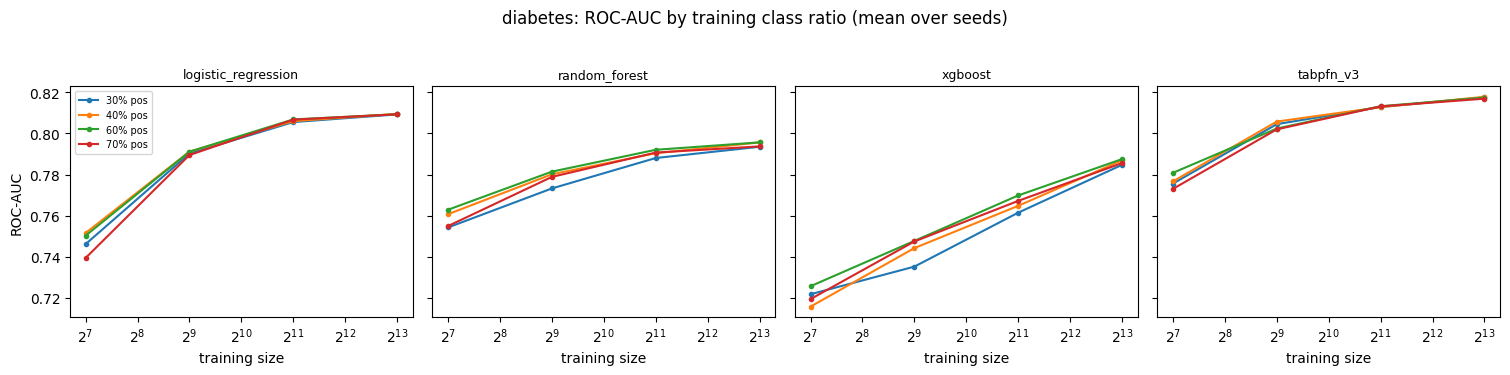

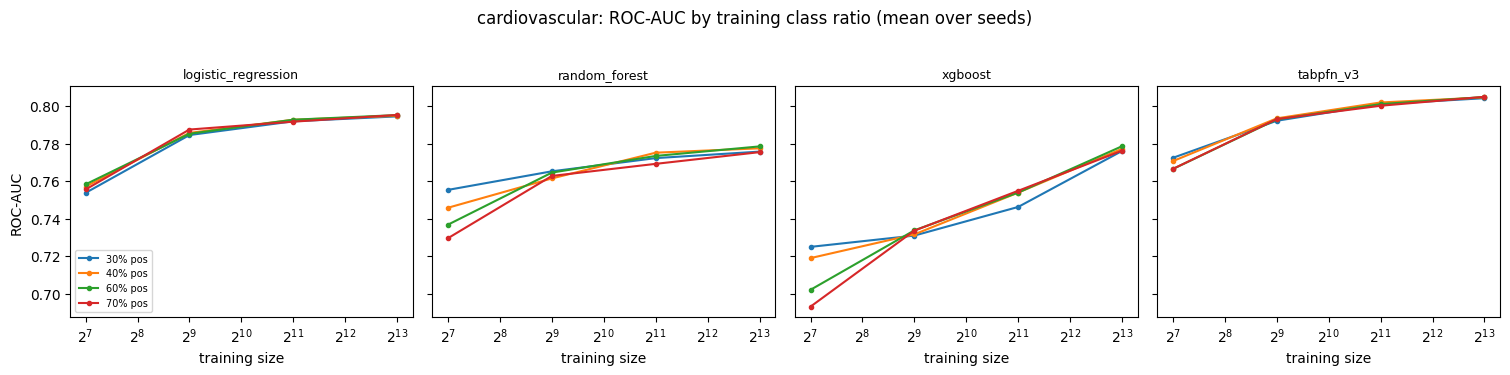

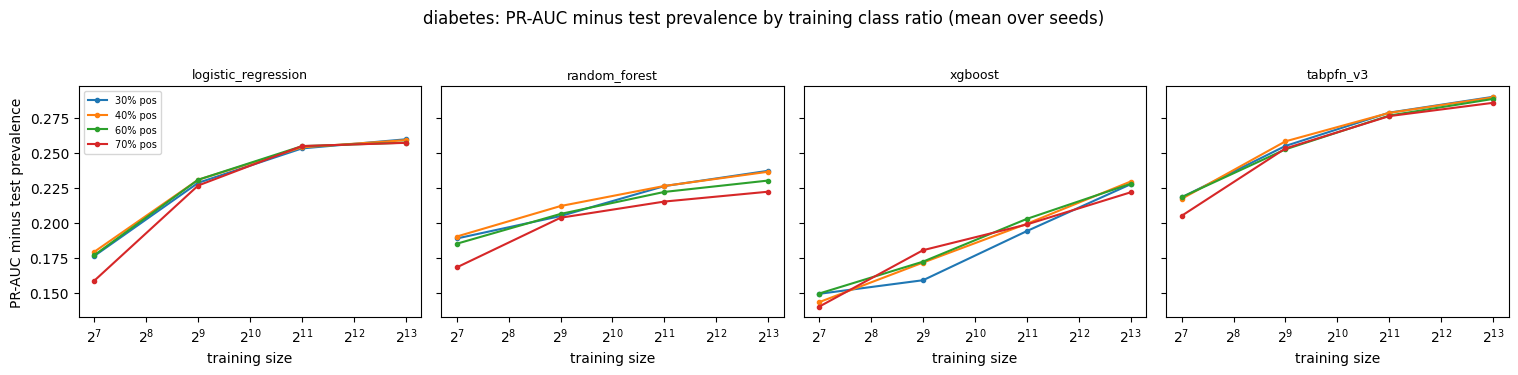

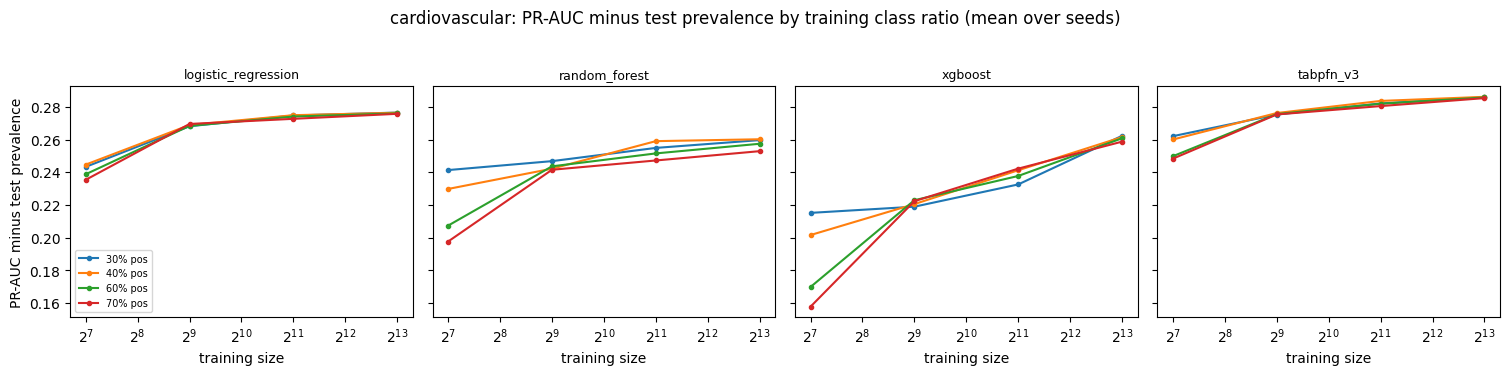

class_ratio                                          0.3     0.4     0.6  \
dataset        model               training_size                           
cardiovascular logistic_regression 128            0.7537  0.7571  0.7582   
                                   512            0.7845  0.7856  0.7852   
                                   2048           0.7918  0.7927  0.7927   
                                   8192           0.7944  0.7947  0.7951   
               random_forest       128            0.7553  0.7458  0.7368   
                                   512            0.7652  0.7614  0.7645   
                                   2048           0.7722  0.7751  0.7734   
                                   8192           0.7757  0.7774  0.7784   
               tabpfn_v3           128            0.7724  0.7706  0.7664   
                                   512            0.7921  0.7934  0.7928   
                                   2048           0.8009  0.8019  0.8010   
                                   8192           0.8041  0.8046  0.8048   
               xgboost             128            0.7249  0.7190  0.7021   
                                   512            0.7310  0.7316  0.7337   
                                   2048           0.7462  0.7538  0.7539   
                                   8192           0.7760  0.7772  0.7785   
diabetes       logistic_regression 128            0.7461  0.7515  0.7502   
                                   512            0.7902  0.7911  0.7911   
                                   2048           0.8055  0.8060  0.8068   
                                   8192           0.8093  0.8095  0.8094   
               random_forest       128            0.7542  0.7607  0.7629   
                                   512            0.7732  0.7801  0.7814   
                                   2048           0.7880  0.7904  0.7921   
                                   8192           0.7935  0.7956  0.7957   
               tabpfn_v3           128            0.7756  0.7767  0.7808   
                                   512            0.8045  0.8058  0.8024   
                                   2048           0.8129  0.8128  0.8133   
                                   8192           0.8176  0.8178  0.8175   
               xgboost             128            0.7217  0.7157  0.7256   
                                   512            0.7351  0.7442  0.7477   
                                   2048           0.7614  0.7647  0.7698   
                                   8192           0.7847  0.7869  0.7875   

class_ratio                                          0.7  
dataset        model               training_size          
cardiovascular logistic_regression 128            0.7555  
                                   512            0.7874  
                                   2048           0.7916  
                                   8192           0.7952  
               random_forest       128            0.7296  
                                   512            0.7627  
                                   2048           0.7692  
                                   8192           0.7754  
               tabpfn_v3           128            0.7665  
                                   512            0.7930  
                                   2048           0.8001  
                                   8192           0.8049  
               xgboost             128            0.6931  
                                   512            0.7336  
                                   2048           0.7548  
                                   8192           0.7762  
diabetes       logistic_regression 128            0.7394  
                                   512            0.7895  
                                   2048           0.8067  
                                   8192           0.8093  
               random_forest       128            0.7549  
                                   512            0.7788  

In [16]:
def plot_learning_curves(metric, ylabel, name):
    for ds in EXPECTED_DATASETS:
        fig, axes = plt.subplots(1, len(MODEL_ORDER), figsize=(3.8 * len(MODEL_ORDER), 3.6), sharey=True)
        axes = np.atleast_1d(axes)
        for ax, m in zip(axes, MODEL_ORDER):
            sub = df[(df.dataset == ds) & (df.model == m)]
            for r in CLASS_RATIOS:
                g = sub[sub.class_ratio == r].groupby("training_size")[metric].mean()
                ax.plot(g.index, g.values, marker="o", ms=3, label=f"{int(round(r * 100))}% pos")
            ax.set_xscale("log", base=2)
            ax.set_title(m, fontsize=9)
            ax.set_xlabel("training size")
        axes[0].set_ylabel(ylabel)
        axes[0].legend(fontsize=7)
        fig.suptitle(f"{ds}: {ylabel} by training class ratio (mean over seeds)", y=1.03)
        fig.tight_layout()
        savefig(fig, f"{name}_{ds}")


plot_learning_curves("roc_auc", "ROC-AUC", "lc_roc")
plot_learning_curves("pr_auc_lift", "PR-AUC minus test prevalence", "lc_prlift")

summary_roc = (df.groupby(["dataset", "model", "training_size", "class_ratio"])["roc_auc"].mean()
               .unstack("class_ratio").round(4))
display(summary_roc)

### B. Paired sensitivity to the class ratio
For each (dataset, model, size, seed) the difference to the 50/50 run is computed. Because subsets are
paired across ratios (shared rows), differences are less noisy than comparing unpaired means.
With few seeds, treat these as descriptive; the standard deviation across seeds is shown.

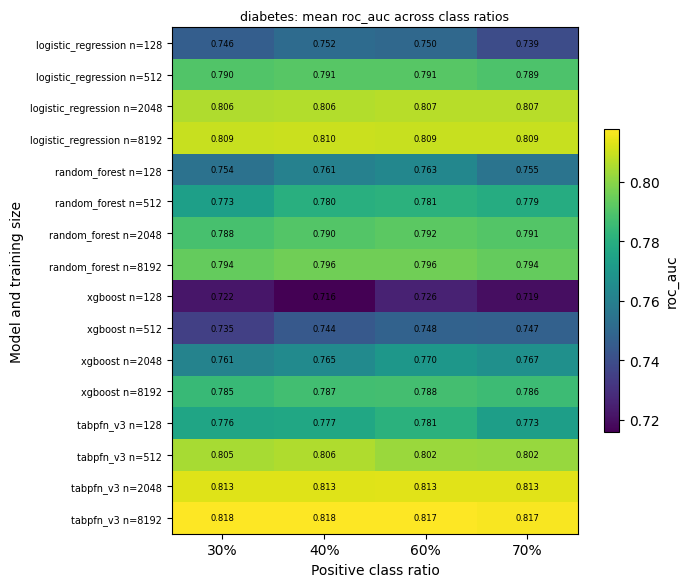

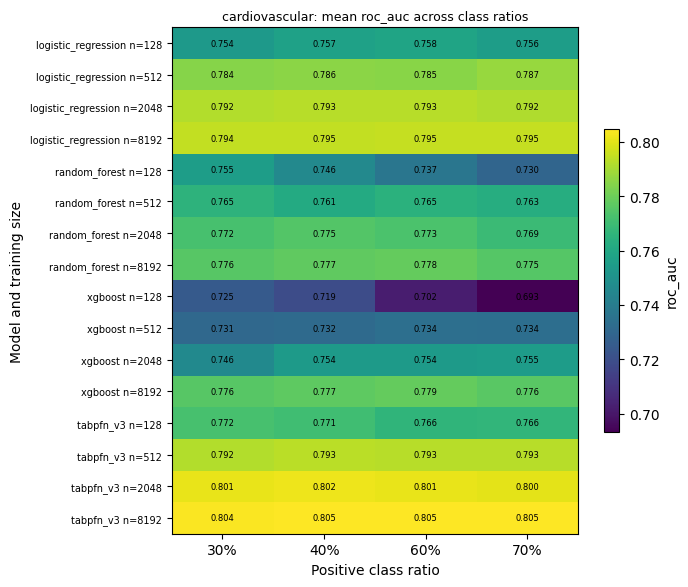

,dataset,model,training_size,class_ratio,mean,std,count
0,cardiovascular,logistic_regression,128,0.3,0.7537,0.0124,5
1,cardiovascular,logistic_regression,128,0.4,0.7571,0.0090,5
2,cardiovascular,logistic_regression,128,0.6,0.7582,0.0266,5
3,cardiovascular,logistic_regression,128,0.7,0.7555,0.0356,5
16,cardiovascular,random_forest,128,0.3,0.7553,0.0074,5
...,...,...,...,...,...,...,...
111,diabetes,tabpfn_v3,8192,0.7,0.8169,0.0004,5
124,diabetes,xgboost,8192,0.3,0.7847,0.0020,5
125,diabetes,xgboost,8192,0.4,0.7869,0.0018,5
126,diabetes,xgboost,8192,0.6,0.7875,0.0034,5



Best-performing class ratio for each model and training size:


,dataset,model,training_size,class_ratio,mean,std
0,cardiovascular,logistic_regression,128,0.6,0.7582,0.0266
1,cardiovascular,logistic_regression,512,0.7,0.7874,0.0030
2,cardiovascular,logistic_regression,2048,0.6,0.7927,0.0022
3,cardiovascular,logistic_regression,8192,0.7,0.7952,0.0010
4,cardiovascular,random_forest,128,0.3,0.7553,0.0074
5,cardiovascular,random_forest,512,0.3,0.7652,0.0097
6,cardiovascular,random_forest,2048,0.4,0.7751,0.0039
7,cardiovascular,random_forest,8192,0.6,0.7784,0.0013
8,cardiovascular,tabpfn_v3,128,0.3,0.7724,0.0076
9,cardiovascular,tabpfn_v3,512,0.4,0.7934,0.0036


In [18]:
# ============================================================
# Class-ratio analysis: ROC-AUC performance
# ============================================================

# ------------------------------------------------------------
# 1. Aggregate ROC-AUC results
# ------------------------------------------------------------

roc_summary = (
    df.groupby(
        ["dataset", "model", "training_size", "class_ratio"]
    )["roc_auc"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

# ------------------------------------------------------------
# 2. Generate ROC-AUC heatmaps
# ------------------------------------------------------------

def heatmap_performance(metric, name):

    agg = (
        df.groupby(
            ["dataset", "model", "training_size", "class_ratio"]
        )[metric]
        .mean()
        .reset_index()
    )

    for ds in EXPECTED_DATASETS:

        sub = agg[agg.dataset == ds]

        piv = sub.pivot_table(
            index=["model", "training_size"],
            columns="class_ratio",
            values=metric
        )

        piv = piv.reindex(
            [(m, s) for m in MODEL_ORDER for s in SIZES]
        )

        # Handle missing or entirely invalid values safely
        values = piv.to_numpy(dtype=float)

        if not np.isfinite(values).any():
            print(f"Skipping {ds}: no valid {metric} values.")
            continue

        vmin = np.nanmin(values)
        vmax = np.nanmax(values)

        fig, ax = plt.subplots(
            figsize=(1.0 * len(CLASS_RATIOS) + 3,
                     0.28 * len(piv) + 1.5)
        )

        im = ax.imshow(
            values,
            cmap="viridis",
            vmin=vmin,
            vmax=vmax if vmax > vmin else vmin + 1e-3,
            aspect="auto"
        )

        ax.set_xticks(
            range(len(piv.columns)),
            [f"{int(round(c * 100))}%" for c in piv.columns]
        )

        ax.set_yticks(
            range(len(piv)),
            [f"{m} n={s}" for m, s in piv.index],
            fontsize=7
        )

        # Add numerical values to heatmap cells
        for i in range(piv.shape[0]):
            for j in range(piv.shape[1]):

                v = values[i, j]

                if np.isfinite(v):
                    ax.text(
                        j, i, f"{v:.3f}",
                        ha="center",
                        va="center",
                        fontsize=6
                    )

        ax.set_xlabel("Positive class ratio")
        ax.set_ylabel("Model and training size")

        ax.set_title(
            f"{ds}: mean {metric} across class ratios",
            fontsize=9
        )

        fig.colorbar(im, ax=ax, shrink=0.6, label=metric)

        fig.tight_layout()

        savefig(fig, f"{name}_{ds}")


# Generate ROC-AUC heatmaps
heatmap_performance("roc_auc", "roc_auc_performance")


# ------------------------------------------------------------
# 3. Display ROC-AUC summary for selected training sizes
# ------------------------------------------------------------

sens = (
    roc_summary[
        roc_summary.training_size.isin(FOCUS_SIZES)
    ]
    .sort_values(
        ["dataset", "training_size", "model", "class_ratio"]
    )
    .round(4)
)

display(sens)


# ------------------------------------------------------------
# 4. Identify the best class ratio for each model
# ------------------------------------------------------------

best_ratios = (
    roc_summary
    .sort_values("mean", ascending=False)
    .groupby(
        ["dataset", "model", "training_size"],
        as_index=False
    )
    .first()
)

print("\nBest-performing class ratio for each model and training size:")

display(
    best_ratios[
        [
            "dataset",
            "model",
            "training_size",
            "class_ratio",
            "mean",
            "std"
        ]
    ].round(4)
)

### C. Threshold-dependent metrics: raw vs prior-corrected
Raw metrics at threshold 0.5 mix the effect of the model with the effect of the training prior. The
corrected versions answer: *if the training prior is accounted for, does the ratio still matter?*


=== training size 512: mean over seeds ===


balanced_accuracy_raw  \
dataset        model               class_ratio                          
cardiovascular logistic_regression 0.3                          0.665   
                                   0.4                          0.704   
                                   0.6                          0.711   
                                   0.7                          0.666   
               random_forest       0.3                          0.679   
                                   0.4                          0.697   
                                   0.6                          0.692   
                                   0.7                          0.659   
               tabpfn_v3           0.3                          0.686   
                                   0.4                          0.714   
                                   0.6                          0.716   
                                   0.7                          0.666   
               xgboost             0.3                          0.654   
                                   0.4                          0.671   
                                   0.6                          0.668   
                                   0.7                          0.645   
diabetes       logistic_regression 0.3                          0.665   
                                   0.4                          0.705   
                                   0.6                          0.716   
                                   0.7                          0.694   
               random_forest       0.3                          0.651   
                                   0.4                          0.700   
                                   0.6                          0.704   
                                   0.7                          0.673   
               tabpfn_v3           0.3                          0.674   
                                   0.4                          0.721   
                                   0.6                          0.722   
                                   0.7                          0.697   
               xgboost             0.3                          0.640   
                                   0.4                          0.670   
                                   0.6                          0.682   
                                   0.7                          0.668   

                                                balanced_accuracy_corr  \
dataset        model               class_ratio                           
cardiovascular logistic_regression 0.3                           0.719   
                                   0.4                           0.720   
                                   0.6                           0.719   
                                   0.7                           0.722   
               random_forest       0.3                           0.706   
                                   0.4                           0.702   
                                   0.6                           0.706   
                                   0.7                           0.704   
               tabpfn_v3           0.3                           0.724   
                                   0.4                           0.725   
                                   0.6                           0.726   
                                   0.7                           0.725   
               xgboost             0.3                           0.670   
                                   0.4                           0.674   
                                   0.6                           0.673   
                                   0.7                           0.666   
diabetes       logistic_regression 0.3                           0.573   
                                   0.4                           0.584   
                                   0.6                           0.594   
           


=== training size 8192: mean over seeds ===


balanced_accuracy_raw  \
dataset        model               class_ratio                          
cardiovascular logistic_regression 0.3                          0.670   
                                   0.4                          0.712   
                                   0.6                          0.716   
                                   0.7                          0.661   
               random_forest       0.3                          0.695   
                                   0.4                          0.715   
                                   0.6                          0.704   
                                   0.7                          0.669   
               tabpfn_v3           0.3                          0.710   
                                   0.4                          0.727   
                                   0.6                          0.726   
                                   0.7                          0.687   
               xgboost             0.3                          0.689   
                                   0.4                          0.710   
                                   0.6                          0.706   
                                   0.7                          0.671   
diabetes       logistic_regression 0.3                          0.675   
                                   0.4                          0.718   
                                   0.6                          0.731   
                                   0.7                          0.709   
               random_forest       0.3                          0.675   
                                   0.4                          0.713   
                                   0.6                          0.718   
                                   0.7                          0.694   
               tabpfn_v3           0.3                          0.689   
                                   0.4                          0.728   
                                   0.6                          0.733   
                                   0.7                          0.707   
               xgboost             0.3                          0.671   
                                   0.4                          0.704   
                                   0.6                          0.715   
                                   0.7                          0.698   

                                                balanced_accuracy_corr  \
dataset        model               class_ratio                           
cardiovascular logistic_regression 0.3                           0.729   
                                   0.4                           0.729   
                                   0.6                           0.728   
                                   0.7                           0.728   
               random_forest       0.3                           0.716   
                                   0.4                           0.716   
                                   0.6                           0.717   
                                   0.7                           0.713   
               tabpfn_v3           0.3                           0.734   
                                   0.4                           0.736   
                                   0.6                           0.737   
                                   0.7                           0.737   
               xgboost             0.3                           0.714   
                                   0.4                           0.716   
                                   0.6                           0.716   
                                   0.7                           0.713   
diabetes       logistic_regression 0.3                           0.569   
                                   0.4                           0.572   
                                   0.6                           0.578   
           

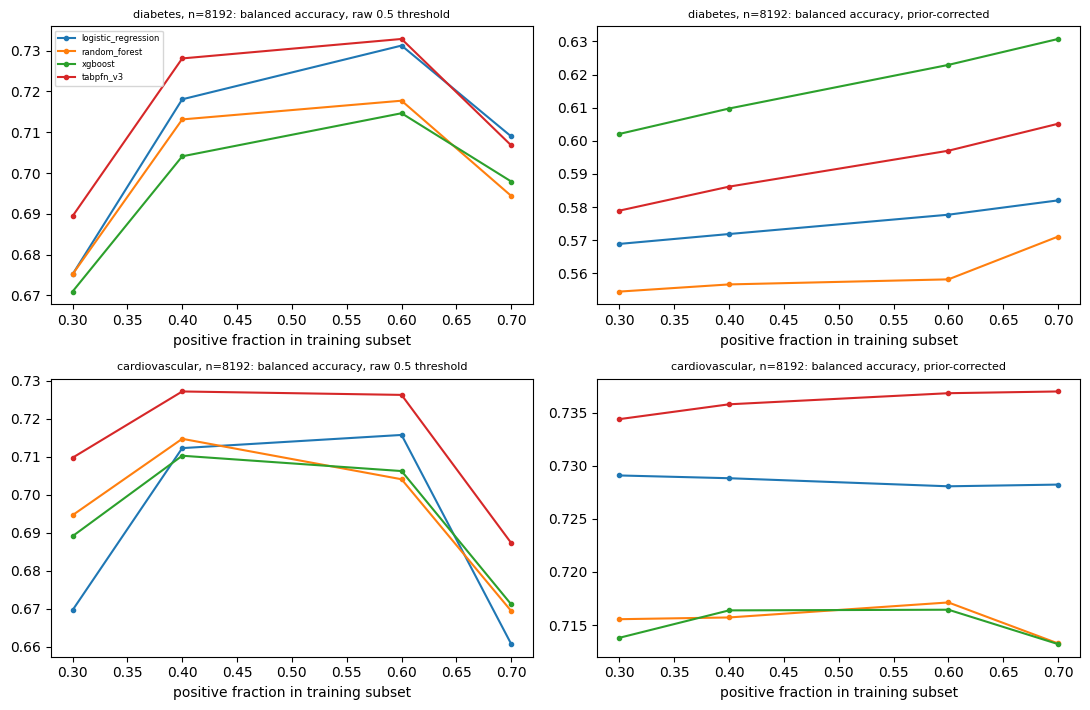

In [19]:
thr_cols = ["balanced_accuracy_raw", "balanced_accuracy_corr", "recall_raw", "recall_corr",
            "precision_raw", "precision_corr", "f1_raw", "f1_corr"]
for s in FOCUS_SIZES[-2:]:
    print(f"\n=== training size {s}: mean over seeds ===")
    t = (df[df.training_size == s].groupby(["dataset", "model", "class_ratio"])[thr_cols].mean().round(3))
    display(t)

fig, axes = plt.subplots(len(EXPECTED_DATASETS), 2, figsize=(11, 3.6 * len(EXPECTED_DATASETS)), squeeze=False)
s_plot = FOCUS_SIZES[-1]
for i, ds in enumerate(EXPECTED_DATASETS):
    for j, (col, ttl) in enumerate([("balanced_accuracy_raw", "balanced accuracy, raw 0.5 threshold"),
                                    ("balanced_accuracy_corr", "balanced accuracy, prior-corrected")]):
        ax = axes[i, j]
        for m in MODEL_ORDER:
            g = df[(df.dataset == ds) & (df.model == m) & (df.training_size == s_plot)].groupby("class_ratio")[col].mean()
            ax.plot(g.index, g.values, marker="o", ms=3, label=m)
        ax.set_title(f"{ds}, n={s_plot}: {ttl}", fontsize=8)
        ax.set_xlabel("positive fraction in training subset")
axes[0, 0].legend(fontsize=6)
fig.tight_layout()
savefig(fig, "balanced_accuracy_raw_vs_corrected")

### D. Probability quality (prior-corrected)
Log-loss, Brier score and ECE are computed after prior correction to the test prevalence. This is the
fair view of calibration, because the uncorrected probabilities are by construction biased towards the
training prior.


=== training size 512: mean over seeds ===


log_loss_corr  brier_corr  \
dataset        model               class_ratio                              
cardiovascular logistic_regression 0.3                 0.5687      0.1901   
                                   0.4                 0.5680      0.1897   
                                   0.6                 0.5687      0.1897   
                                   0.7                 0.5666      0.1887   
               random_forest       0.3                 0.6110      0.1991   
                                   0.4                 0.5990      0.2000   
                                   0.6                 0.5933      0.1984   
                                   0.7                 0.6042      0.1995   
               tabpfn_v3           0.3                 0.5577      0.1865   
                                   0.4                 0.5548      0.1857   
                                   0.6                 0.5568      0.1860   
                                   0.7                 0.5556      0.1855   
               xgboost             0.3                 0.8718      0.2513   
                                   0.4                 0.8382      0.2454   
                                   0.6                 0.8328      0.2449   
                                   0.7                 0.8480      0.2501   
diabetes       logistic_regression 0.3                 0.3589      0.1122   
                                   0.4                 0.3596      0.1125   
                                   0.6                 0.3642      0.1142   
                                   0.7                 0.3681      0.1153   
               random_forest       0.3                 0.3662      0.1132   
                                   0.4                 0.3620      0.1124   
                                   0.6                 0.3643      0.1136   
                                   0.7                 0.3722      0.1148   
               tabpfn_v3           0.3                 0.3467      0.1083   
                                   0.4                 0.3462      0.1082   
                                   0.6                 0.3521      0.1104   
                                   0.7                 0.3538      0.1111   
               xgboost             0.3                 0.5304      0.1515   
                                   0.4                 0.5505      0.1613   
                                   0.6                 0.6531      0.1918   
                                   0.7                 0.7237      0.2120   

                                                ece_corr  
dataset        model               class_ratio            
cardiovascular logistic_regression 0.3            0.0315  
                                   0.4            0.0333  
                                   0.6            0.0329  
                                   0.7            0.0318  
               random_forest       0.3            0.0440  
                                   0.4            0.0377  
                                   0.6            0.0352  
                                   0.7            0.0353  
               tabpfn_v3           0.3            0.0328  
                                   0.4            0.0323  
                                   0.6            0.0314  
                                   0.7            0.0287  
               xgboost             0.3            0.1886  
                                   0.4            0.1783  
                                   0.6            0.1793  
                                   0.7            0.1898  
diabetes       logistic_regression 0.3            0.0183  
                                   0.4            0.0213  
                                   0.6            0.0282  
                                   0.7            0.0304  
               random_forest       0.3            0.0098  
                                   0.4            0.0101  
             


=== training size 8192: mean over seeds ===


log_loss_corr  brier_corr  \
dataset        model               class_ratio                              
cardiovascular logistic_regression 0.3                 0.5586      0.1860   
                                   0.4                 0.5582      0.1858   
                                   0.6                 0.5577      0.1855   
                                   0.7                 0.5575      0.1854   
               random_forest       0.3                 0.6020      0.1949   
                                   0.4                 0.5849      0.1933   
                                   0.6                 0.5819      0.1928   
                                   0.7                 0.5937      0.1946   
               tabpfn_v3           0.3                 0.5402      0.1801   
                                   0.4                 0.5386      0.1794   
                                   0.6                 0.5382      0.1792   
                                   0.7                 0.5389      0.1793   
               xgboost             0.3                 0.5911      0.1960   
                                   0.4                 0.5877      0.1949   
                                   0.6                 0.5888      0.1944   
                                   0.7                 0.5970      0.1967   
diabetes       logistic_regression 0.3                 0.3449      0.1077   
                                   0.4                 0.3450      0.1078   
                                   0.6                 0.3456      0.1081   
                                   0.7                 0.3459      0.1083   
               random_forest       0.3                 0.3561      0.1099   
                                   0.4                 0.3540      0.1098   
                                   0.6                 0.3548      0.1107   
                                   0.7                 0.3610      0.1121   
               tabpfn_v3           0.3                 0.3374      0.1051   
                                   0.4                 0.3373      0.1052   
                                   0.6                 0.3381      0.1056   
                                   0.7                 0.3395      0.1062   
               xgboost             0.3                 0.3790      0.1173   
                                   0.4                 0.3785      0.1178   
                                   0.6                 0.3890      0.1219   
                                   0.7                 0.3982      0.1258   

                                                ece_corr  
dataset        model               class_ratio            
cardiovascular logistic_regression 0.3            0.0370  
                                   0.4            0.0358  
                                   0.6            0.0334  
                                   0.7            0.0324  
               random_forest       0.3            0.0446  
                                   0.4            0.0385  
                                   0.6            0.0318  
                                   0.7            0.0345  
               tabpfn_v3           0.3            0.0266  
                                   0.4            0.0191  
                                   0.6            0.0155  
                                   0.7            0.0177  
               xgboost             0.3            0.0544  
                                   0.4            0.0501  
                                   0.6            0.0509  
                                   0.7            0.0603  
diabetes       logistic_regression 0.3            0.0114  
                                   0.4            0.0114  
                                   0.6            0.0121  
                                   0.7            0.0129  
               random_forest       0.3            0.0074  
                                   0.4            0.0061  
             

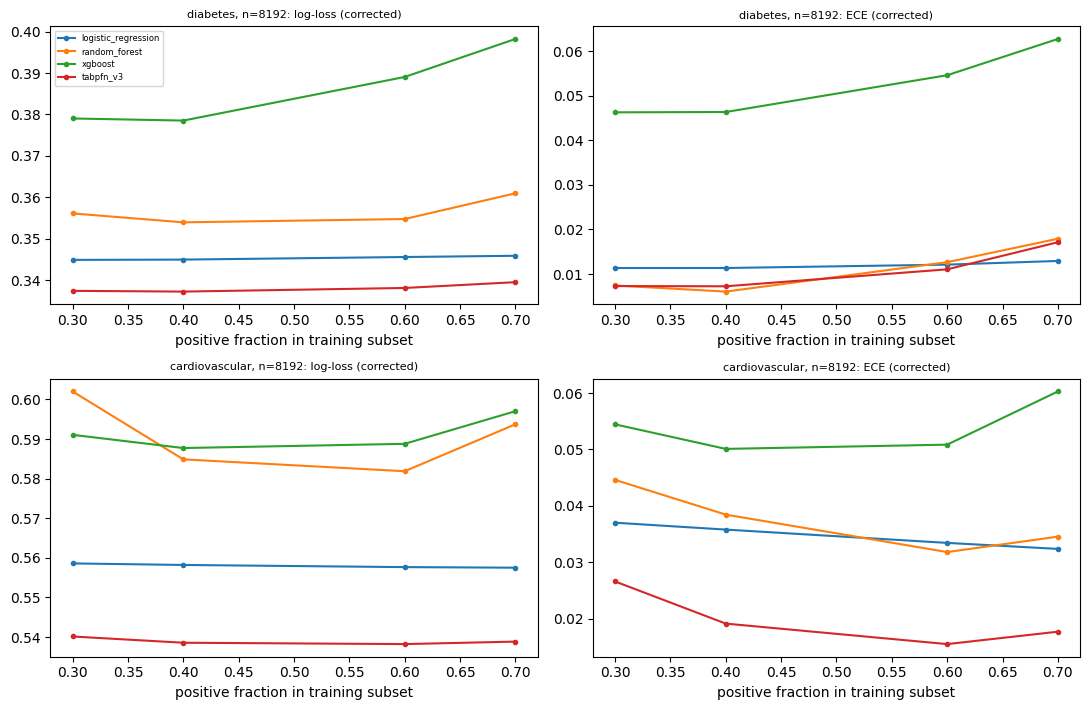

In [20]:
cal_cols = ["log_loss_corr", "brier_corr", "ece_corr"]
for s in FOCUS_SIZES[-2:]:
    print(f"\n=== training size {s}: mean over seeds ===")
    display(df[df.training_size == s].groupby(["dataset", "model", "class_ratio"])[cal_cols].mean().round(4))

fig, axes = plt.subplots(len(EXPECTED_DATASETS), 2, figsize=(11, 3.6 * len(EXPECTED_DATASETS)), squeeze=False)
for i, ds in enumerate(EXPECTED_DATASETS):
    for j, (col, ttl) in enumerate([("log_loss_corr", "log-loss (corrected)"), ("ece_corr", "ECE (corrected)")]):
        ax = axes[i, j]
        for m in MODEL_ORDER:
            g = df[(df.dataset == ds) & (df.model == m) & (df.training_size == s_plot)].groupby("class_ratio")[col].mean()
            ax.plot(g.index, g.values, marker="o", ms=3, label=m)
        ax.set_title(f"{ds}, n={s_plot}: {ttl}", fontsize=8)
        ax.set_xlabel("positive fraction in training subset")
axes[0, 0].legend(fontsize=6)
fig.tight_layout()
savefig(fig, "calibration_vs_ratio")

### E. Does TabPFN's advantage depend on the training ratio?
Difference in ROC-AUC (TabPFN minus baseline), paired by seed, with the number of seeds in which
TabPFN is better. The "best classical (by mean)" baseline is chosen per cell on the mean, which is
slightly optimistic for the baseline and therefore conservative for TabPFN.

,dataset,class_ratio,training_size,best_classical,diff_vs_best_classical,wins_vs_best_classical,n_seeds
0,cardiovascular,0.3,128,random_forest,0.0171,5,5
1,cardiovascular,0.3,512,logistic_regression,0.0076,5,5
2,cardiovascular,0.3,2048,logistic_regression,0.0091,5,5
3,cardiovascular,0.3,8192,logistic_regression,0.0097,5,5
4,cardiovascular,0.4,128,logistic_regression,0.0136,5,5
5,cardiovascular,0.4,512,logistic_regression,0.0077,5,5
6,cardiovascular,0.4,2048,logistic_regression,0.0092,5,5
7,cardiovascular,0.4,8192,logistic_regression,0.0098,5,5
8,cardiovascular,0.6,128,logistic_regression,0.0082,3,5
9,cardiovascular,0.6,512,logistic_regression,0.0076,5,5


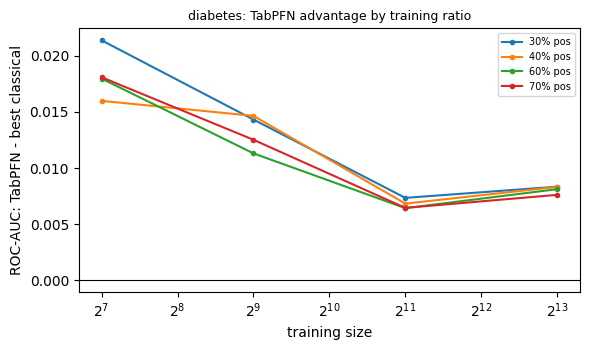

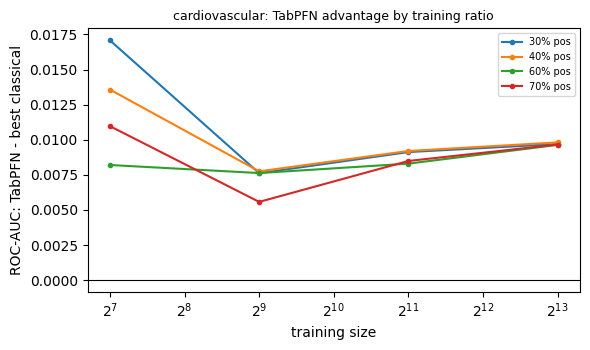

In [21]:
if "tabpfn_v3" in MODEL_ORDER:
    classical = [m for m in MODEL_ORDER if m != "tabpfn_v3"]
    piv = df.pivot_table(index=["dataset", "class_ratio", "training_size", "subset_seed"],
                         columns="model", values="roc_auc")
    cell_means = piv.groupby(level=["dataset", "class_ratio", "training_size"]).mean()
    best_name = cell_means[classical].idxmax(axis=1)

    rows = []
    for (ds, r, n), g in piv.groupby(level=["dataset", "class_ratio", "training_size"]):
        row = {"dataset": ds, "class_ratio": r, "training_size": n,
               "best_classical": best_name.loc[(ds, r, n)]}
        diff_best = g["tabpfn_v3"] - g[row["best_classical"]]
        row["diff_vs_best_classical"] = diff_best.mean()
        row["wins_vs_best_classical"] = int((diff_best > 0).sum())
        row["n_seeds"] = len(g)
        rows.append(row)
    tab_cmp = pd.DataFrame(rows)
    display(tab_cmp.round(4))

    for ds in EXPECTED_DATASETS:
        sub = tab_cmp[tab_cmp.dataset == ds]
        fig, ax = plt.subplots(figsize=(6, 3.6))
        for r in CLASS_RATIOS:
            g = sub[sub.class_ratio == r]
            ax.plot(g.training_size, g.diff_vs_best_classical, marker="o", ms=3, label=f"{int(round(r * 100))}% pos")
        ax.axhline(0, color="black", lw=0.8)
        ax.set_xscale("log", base=2)
        ax.set_xlabel("training size")
        ax.set_ylabel("ROC-AUC: TabPFN - best classical")
        ax.set_title(f"{ds}: TabPFN advantage by training ratio", fontsize=9)
        ax.legend(fontsize=7)
        fig.tight_layout()
        savefig(fig, f"tabpfn_advantage_{ds}")
else:
    print("TabPFN not included; skipping.")

### Automatically generated key findings
Printed from the data so the numbers in the thesis text cannot drift from the results.

In [22]:
print("KEY FINDINGS (descriptive; seeds =", len(SEEDS), ")\n")
d_roc = paired_delta("roc_auc")
d_ll = paired_delta("log_loss_corr")
d_bal_raw = paired_delta("balanced_accuracy_raw")
d_bal_cor = paired_delta("balanced_accuracy_corr")

for ds in EXPECTED_DATASETS:
    print(f"[{ds}]  test prevalence = {POOLS[ds]['test_prevalence']:.3f}")
    a = d_roc[d_roc.dataset == ds].groupby(["model", "training_size", "class_ratio"])["delta"].mean()
    print(f"  ROC-AUC change vs 50/50: mean |delta| = {a.abs().mean():.4f}, max |delta| = {a.abs().max():.4f}")
    for lbl, dd in (("raw balanced accuracy", d_bal_raw), ("corrected balanced accuracy", d_bal_cor)):
        b = dd[dd.dataset == ds].groupby(["model", "training_size", "class_ratio"])["delta"].mean()
        print(f"  {lbl}: mean |delta| = {b.abs().mean():.4f}")
    ll = df[(df.dataset == ds) & (df.training_size == s_plot)].groupby(["model", "class_ratio"])["log_loss_corr"].mean().unstack()
    print(f"  best ratio by corrected log-loss at n={s_plot}: " +
          ", ".join(f"{m}: {int(round(ll.loc[m].idxmin() * 100))}%" for m in ll.index))
    if "tabpfn_v3" in MODEL_ORDER:
        sub = tab_cmp[(tab_cmp.dataset == ds)]
        for r in CLASS_RATIOS:
            g = sub[sub.class_ratio == r]
            pos = g[g.diff_vs_best_classical > 0].training_size.tolist()
            print(f"  r={r:.1f}: TabPFN ahead of best classical (mean) at sizes {pos if pos else 'none'}")
    print()

KEY FINDINGS (descriptive; seeds = 5 )

[diabetes]  test prevalence = 0.153
  ROC-AUC change vs 50/50: mean |delta| = nan, max |delta| = nan
  raw balanced accuracy: mean |delta| = nan
  corrected balanced accuracy: mean |delta| = nan
  best ratio by corrected log-loss at n=8192: logistic_regression: 30%, random_forest: 40%, tabpfn_v3: 40%, xgboost: 40%
  r=0.3: TabPFN ahead of best classical (mean) at sizes [128, 512, 2048, 8192]
  r=0.4: TabPFN ahead of best classical (mean) at sizes [128, 512, 2048, 8192]
  r=0.6: TabPFN ahead of best classical (mean) at sizes [128, 512, 2048, 8192]
  r=0.7: TabPFN ahead of best classical (mean) at sizes [128, 512, 2048, 8192]

[cardiovascular]  test prevalence = 0.495
  ROC-AUC change vs 50/50: mean |delta| = nan, max |delta| = nan
  raw balanced accuracy: mean |delta| = nan
  corrected balanced accuracy: mean |delta| = nan
  best ratio by corrected log-loss at n=8192: logistic_regression: 70%, random_forest: 60%, tabpfn_v3: 60%, xgboost: 40%
  r=0

In [23]:
# ============================================================
# Cell 10 - Export all generated figures
# ============================================================

import zipfile
from pathlib import Path

# Folder containing experiment results and figures
FIGURES_DIR = RESULTS_DIR

# Find all PNG figures generated for this study
figure_files = sorted(
    FIGURES_DIR.glob(f"{STUDY_VERSION}_*.png")
)

if not figure_files:
    print("No figures found. Please check whether the plotting cells ran successfully.")

else:
    # Create ZIP archive containing all figures
    ZIP_PATH = FIGURES_DIR / f"{STUDY_VERSION}_all_figures.zip"

    with zipfile.ZipFile(
        ZIP_PATH,
        mode="w",
        compression=zipfile.ZIP_DEFLATED
    ) as zipf:

        for fig_path in figure_files:
            zipf.write(
                fig_path,
                arcname=fig_path.name
            )

    print("=" * 60)
    print("FIGURE EXPORT COMPLETED")
    print("=" * 60)

    print(f"Number of figures exported: {len(figure_files)}")
    print(f"ZIP archive: {ZIP_PATH}")

    print("\nExported figures:")

    for fig_path in figure_files:
        print(f"- {fig_path.name}")

    print("\nAll figures have been collected successfully.")

FIGURE EXPORT COMPLETED
Number of figures exported: 10
ZIP archive: /kaggle/working/class_balance_v1_all_figures.zip

Exported figures:
- class_balance_v1_balanced_accuracy_raw_vs_corrected.png
- class_balance_v1_calibration_vs_ratio.png
- class_balance_v1_lc_prlift_cardiovascular.png
- class_balance_v1_lc_prlift_diabetes.png
- class_balance_v1_lc_roc_cardiovascular.png
- class_balance_v1_lc_roc_diabetes.png
- class_balance_v1_roc_auc_performance_cardiovascular.png
- class_balance_v1_roc_auc_performance_diabetes.png
- class_balance_v1_tabpfn_advantage_cardiovascular.png
- class_balance_v1_tabpfn_advantage_diabetes.png

All figures have been collected successfully.
